# Day 2 · 08 — Bonus: why can we forecast these series at all? (delay embeddings)

Not part of the 4-hour schedule: a notebook to explore after the workshop. It uses no models from the labs and adds
nothing to the leaderboard. The interactive version of the same pictures is on the site:
https://time-series-modeling.github.io/workshops/packt-2026-11/day2/embedding

A forecast is a bet that the future will resemble what followed **similar situations** in the past. Delay
embeddings make that idea visible:

* Write each week as a point made of its recent values, `(x(t), x(t−τ), x(t−2τ), …)`. That point is the
  **state** of the series at week t.
* **Takens (1981)**: for a smooth deterministic system on a compact manifold of dimension d, 2d+1 delayed copies of
  one generic observation give an *embedding*, a one-to-one smooth picture of the hidden state.
  Sauer, Yorke and Casdagli (1991) extended this to fractal attractors (m > 2 × box-counting dimension).
* So if **nearby states have similar futures**, the series is predictable, and you can see it.

Weekly retail sales are not a clean deterministic system: they are counts, driven by prices and promotions, with
93 training weeks. We use the pictures to **look for structure**, not to prove the theorem applies, and we test
every pattern against a "no pattern" baseline: the same values in shuffled order.

| Section | Question |
|---|---|
| 1 | What does a series look like as a cloud of states? |
| 2 | Do similar states have similar futures, more than chance? (one series, then all series) |
| 3 | Do states of *other* items look like this item, and what followed them? |
| 4 | Recurrence plots: has the series been here before? |
| 5 | Choosing τ and m, and why the textbook recipe struggles here |
| 6 | Is the structure nonlinear? S-map against surrogates |

**Packages** (all existing implementations, no hand-written estimators): `teaspoon` (mutual information),
`neurokit2` (false nearest neighbours), `pyEDM` (simplex projection and S-map), `pyunicorn` (recurrence
quantification and IAAFT surrogates), `scikit-learn` (nearest neighbours across items), `joblib` (parallel loop).

```bash
pip install pyEDM teaspoon neurokit2 pyunicorn scikit-learn joblib scipy statsmodels
```

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 100, "axes.prop_cycle": plt.cycler(color=palette)})

panel = bc.load_panel()
train, test = bc.split(panel)
info = bc.series_info(panel).to_pandas().set_index("unique_id")
items = pd.read_csv(bc.DATA_DIR / "items.csv").set_index("item_id")
N_TRAIN = train["ds"].n_unique()
print(f"{panel['unique_id'].n_unique():,} series, {N_TRAIN} training weeks, {bc.H} test weeks")

17,241 series, 93 training weeks, 14 test weeks


### The series we look at

Four items, one per demand type (the same examples as the site), the largest department, the whole store, and two
references with known structure: a yearly cycle with noise, and the x coordinate of the Lorenz system (deterministic
chaos, sampled at the same length and at 1,000 points). Change `EXAMPLES` to look at any other item.

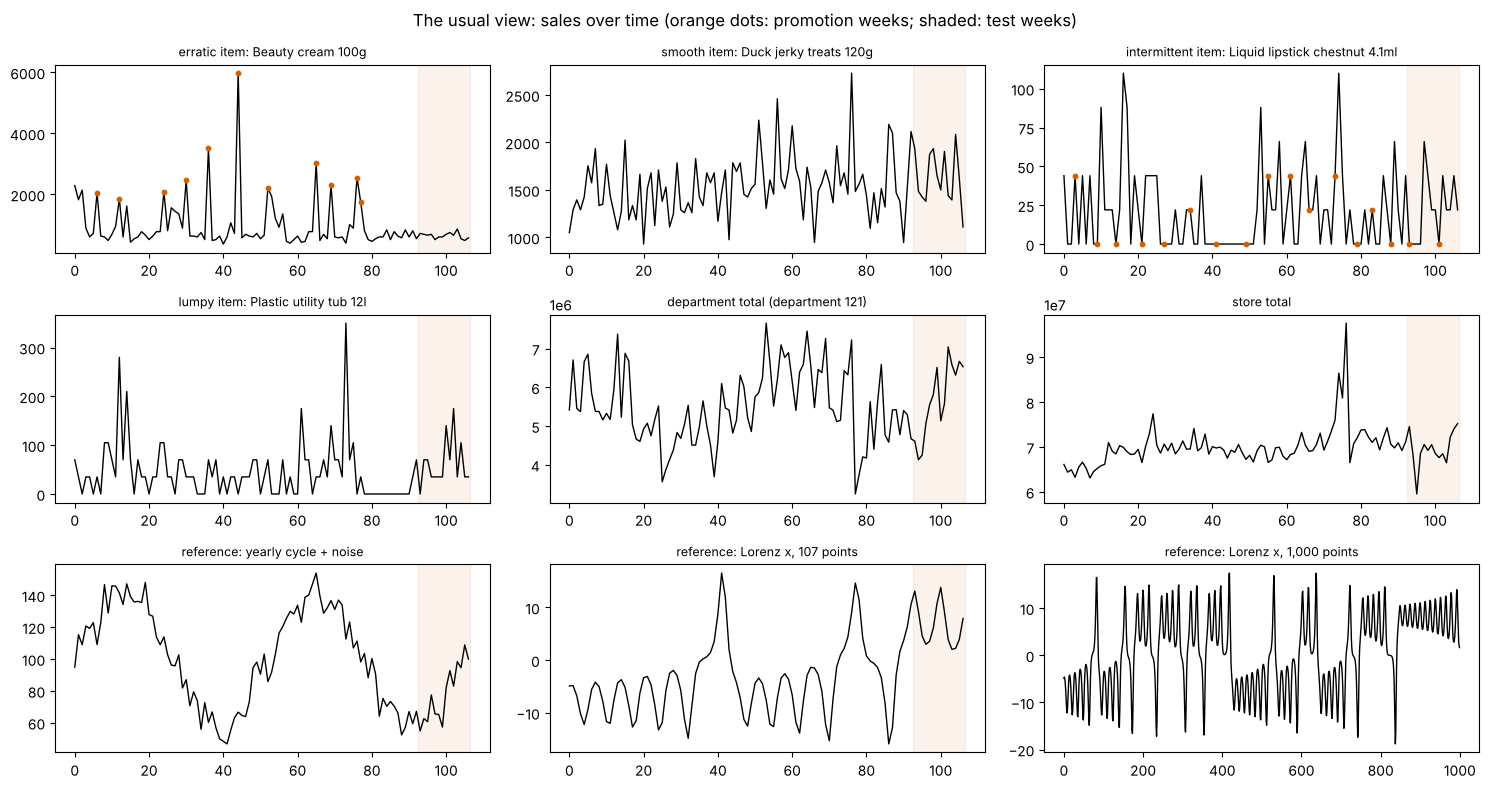

In [2]:
EXAMPLES = {"erratic": "2324_S1", "smooth": "5830_S1", "intermittent": "17249_S1", "lumpy": "9996_S1"}


def item_series(uid):
    s = panel.filter(pl.col("unique_id") == uid).sort("ds")
    return s["y"].to_numpy().astype(float), s["promo"].to_numpy().astype(int)


def desc(uid):
    iid = int(uid.split("_")[0])
    return items.loc[iid, "item_desc"] if iid in items.index else uid


S = {}  # key -> dict(y = full series (train + test), promo, label)
for k, uid in EXAMPLES.items():
    y, pr = item_series(uid)
    S[k] = dict(y=y, promo=pr, label=f"{k} item: {desc(uid)}")
dept = int(panel.group_by("department_id").agg(pl.col("y").sum()).sort("y", descending=True)["department_id"][0])
for k, d in [("department", panel.filter(pl.col("department_id") == dept)), ("store", panel)]:
    g = d.group_by("ds").agg(pl.col("y").sum()).sort("ds")
    S[k] = dict(y=g["y"].to_numpy().astype(float), promo=None, label=f"{k} total" + (f" (department {dept})" if k == "department" else ""))

from scipy.integrate import solve_ivp

n_all = len(S["store"]["y"])
rng = np.random.default_rng(bc.RANDOM_SEED)
t = np.arange(n_all)
S["yearly cycle"] = dict(y=100 + 40 * np.sin(2 * np.pi * t / 52) + 8 * rng.standard_normal(n_all), promo=None,
                         label="reference: yearly cycle + noise")
sol = solve_ivp(lambda _, s: [10 * (s[1] - s[0]), s[0] * (28 - s[2]) - s[1], s[0] * s[1] - 8 / 3 * s[2]],
                [0, 60], [1, 1, 1], t_eval=np.arange(0, 60, 0.05), rtol=1e-9, atol=1e-9)
lx = sol.y[0][200:]
S["lorenz"] = dict(y=lx[: n_all * 2 : 2][:n_all], promo=None, label=f"reference: Lorenz x, {n_all} points")
S["lorenz 1000"] = dict(y=lx[:1000], promo=None, label="reference: Lorenz x, 1,000 points")

fig, axes = plt.subplots(3, 3, figsize=(15, 8))
for ax, (k, s) in zip(axes.flat, S.items()):
    ax.plot(s["y"], lw=1, color="k")
    if s["promo"] is not None:
        ax.scatter(np.where(s["promo"])[0], s["y"][s["promo"] == 1], s=10, color=palette[2], zorder=3)
    if len(s["y"]) == n_all:
        ax.axvspan(N_TRAIN - 0.5, n_all - 0.5, color=palette[2], alpha=0.08)
    ax.set_title(s["label"], fontsize=9)
fig.suptitle("The usual view: sales over time (orange dots: promotion weeks; shaded: test weeks)")
fig.tight_layout()

## 1 · From a line to a cloud of states

Each week t becomes the point `(x(t), x(t−τ), x(t−2τ))`. Points join consecutive weeks. A deterministic system
draws a thin folded surface (the Lorenz butterfly); a cycle draws a loop; noise draws a ball.

Things to try: change `TAU` (1, 4, 13); set `COLOUR = "promo"` for the items.

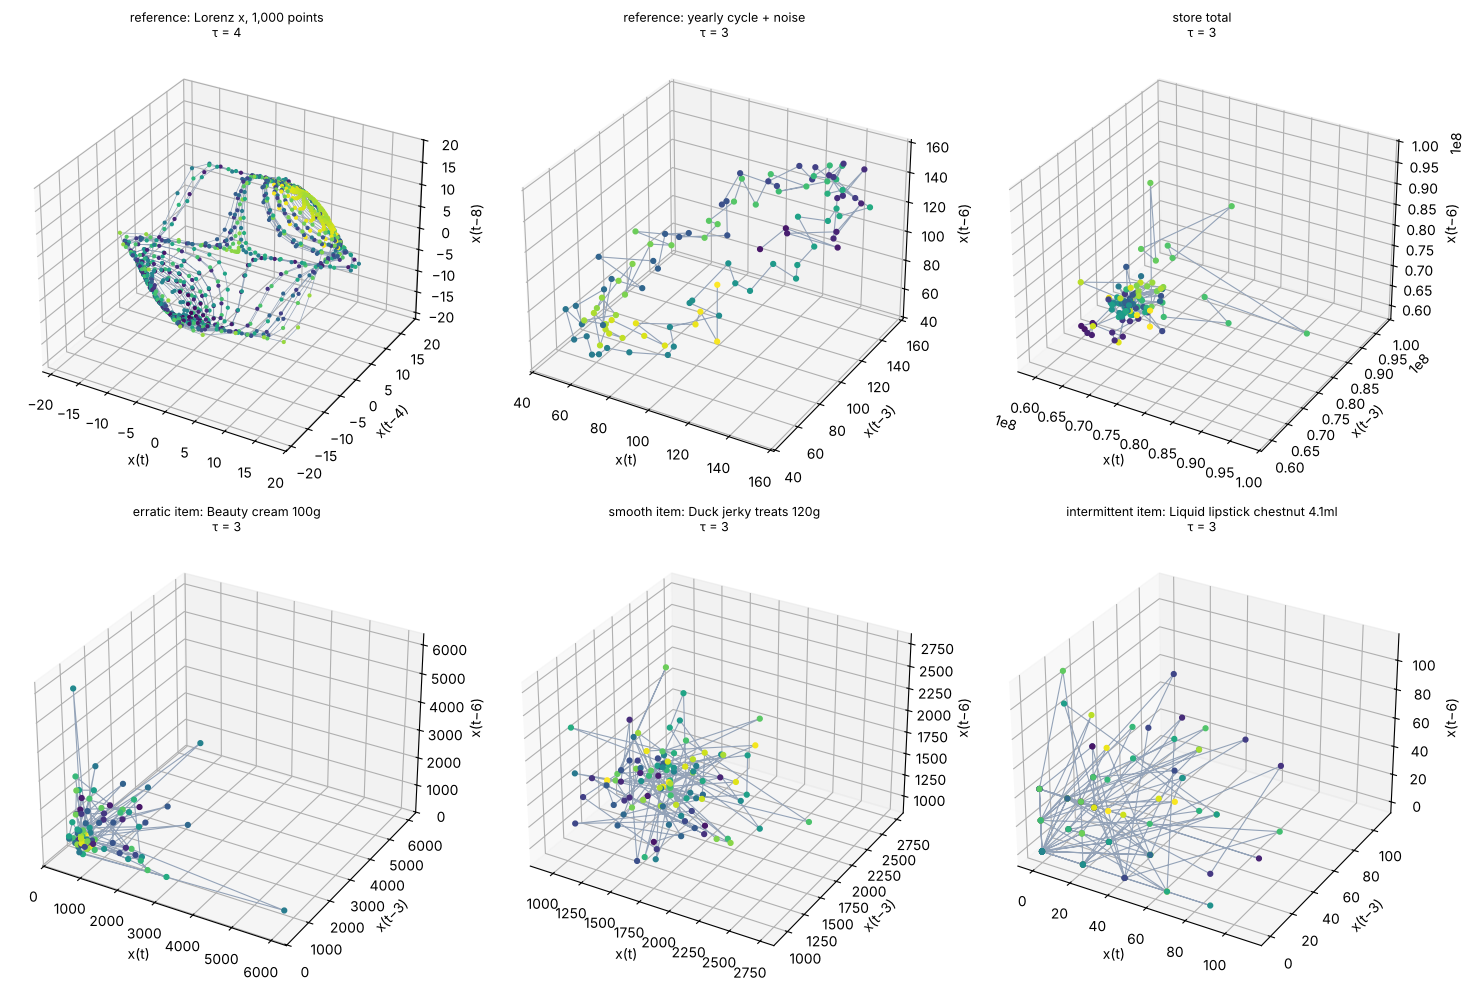

In [3]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)


def embed(y, m, tau):
    """Delay vectors (x(t), x(t-tau), ..., x(t-(m-1)tau)) for every t where all exist; returns (times, vectors)."""
    t0 = (m - 1) * tau
    return np.arange(t0, len(y)), np.stack([y[t0 - j * tau: len(y) - j * tau] for j in range(m)], axis=1)


def portrait(key, tau, ax, colour="time", log=False):
    s = S[key]
    y = np.log1p(np.clip(s["y"], 0, None)) if log else s["y"]
    tt, X = embed(y, 3, tau)
    if colour == "promo" and s["promo"] is not None:
        c = np.where(s["promo"][tt] == 1, palette[2], "#94a3b8")
    elif colour == "split" and len(y) == n_all:
        c = np.where(tt >= N_TRAIN, palette[2], palette[1])
    else:
        c = plt.cm.viridis(tt / tt.max())
    ax.plot(X[:, 0], X[:, 1], X[:, 2], color="#94a3b8", lw=0.5 if len(y) > 300 else 0.8)
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=c, s=4 if len(y) > 300 else 12, depthshade=False)
    ax.set_xlabel("x(t)"); ax.set_ylabel(f"x(t−{tau})"); ax.set_zlabel(f"x(t−{2 * tau})")
    ax.set_title(f"{s['label']}\nτ = {tau}", fontsize=9)


TAU, COLOUR = 3, "time"
fig = plt.figure(figsize=(15, 10))
for i, k in enumerate(["lorenz 1000", "yearly cycle", "store", "erratic", "smooth", "intermittent"]):
    portrait(k, TAU if k != "lorenz 1000" else 4, fig.add_subplot(2, 3, i + 1, projection="3d"), colour=COLOUR)
fig.tight_layout()

**Reading it.** Retail items make a cloud, not a curve. With `COLOUR = "promo"` the promotion weeks sit far out along
each axis in turn: a spike passes through x(t), then x(t−τ), then x(t−2τ), which draws a "star" with arms along the
axes. That pattern is the price calendar, an outside driver, not hidden dynamics, and it is why the models with
promotion inputs win on Day 2.

In Jupyter you can rotate a 3D plot with `%matplotlib widget` (needs `ipympl`). The site has a version with a time
slider.

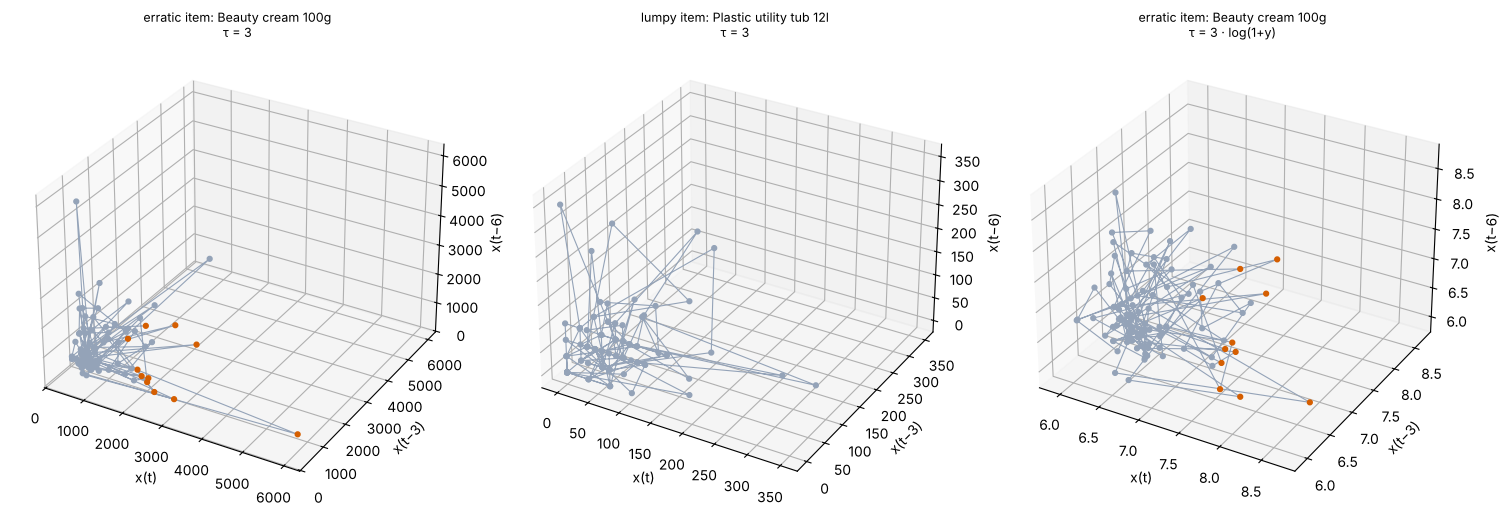

In [4]:
fig = plt.figure(figsize=(15, 5))
for i, k in enumerate(["erratic", "lumpy"]):
    portrait(k, TAU, fig.add_subplot(1, 3, i + 1, projection="3d"), colour="promo")
portrait("erratic", TAU, fig.add_subplot(1, 3, 3, projection="3d"), colour="promo", log=True)
fig.axes[-1].set_title(fig.axes[-1].get_title() + " · log(1+y)", fontsize=9)
fig.tight_layout()

## 2 · Similar states, similar futures

Take "now" (the last training week), find the past weeks whose state is closest to it, and look at what followed
them. Their weighted average is **simplex projection** (Sugihara and May 1990): E+1 nearest neighbours in an
E-dimensional embedding, weights exp(−d/d_min). Here the neighbours are found with scikit-learn so that we can plot
them; the skill numbers below use `pyEDM`, the reference implementation.

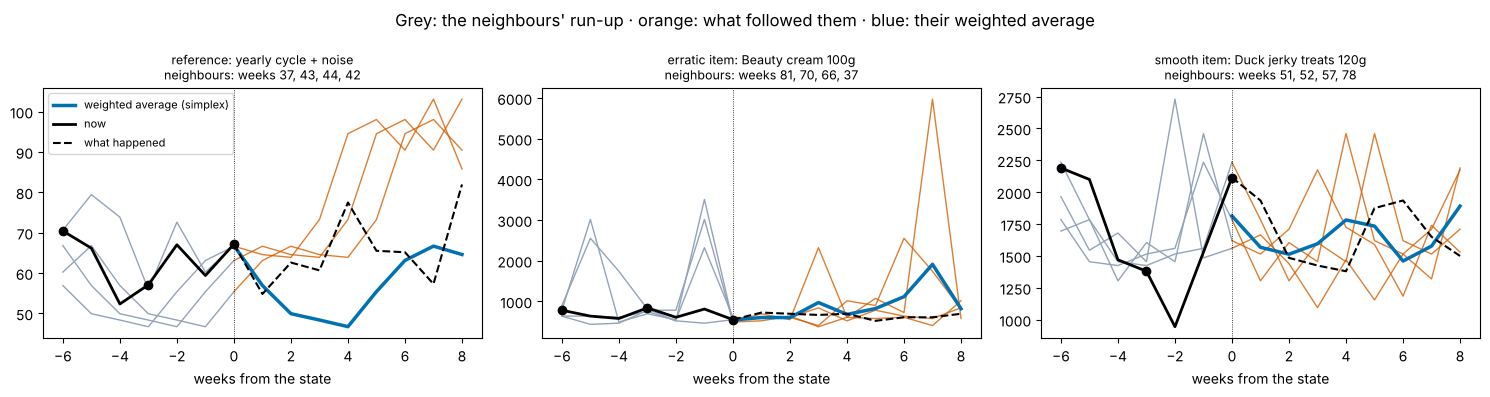

In [5]:
from sklearn.neighbors import NearestNeighbors

HF = 8  # weeks after each neighbour to show


def own_neighbours(key, m=3, tau=TAU, now=None):
    y = S[key]["y"]
    now = N_TRAIN - 1 if now is None else now
    tt, X = embed(y, m, tau)
    lib = tt + HF <= now                      # only states whose next HF weeks were known at "now"
    nn = NearestNeighbors(n_neighbors=m + 1).fit(X[lib])
    d, i = nn.kneighbors(X[tt == now])
    d, nb = d[0], tt[lib][i[0]]
    w = np.exp(-d / max(d[0], 1e-12)); w /= w.sum()
    return y, now, nb, w, m, tau


def plot_own_neighbours(key, ax, **kw):
    y, now, nb, w, m, tau = own_neighbours(key, **kw)
    back, h = (m - 1) * tau, np.arange(-(m - 1) * tau, HF + 1)
    for j in nb:
        ax.plot(h[h <= 0], y[j + h[h <= 0]], color="#94a3b8", lw=1)
        ax.plot(h[h >= 0], y[j + h[h >= 0]], color=palette[2], lw=1, alpha=0.8)
    ax.plot(h[h >= 0], sum(wi * y[j + h[h >= 0]] for wi, j in zip(w, nb)), color=palette[1], lw=2.5, label="weighted average (simplex)")
    ax.plot(h[h <= 0], y[now + h[h <= 0]], color="k", lw=2, label="now")
    fut = h[(h >= 0) & (now + h < len(y))]
    ax.plot(fut, y[now + fut], "k--", lw=1.5, label="what happened")
    ax.scatter(-np.arange(m) * tau, y[now - np.arange(m) * tau], color="k", zorder=3)
    ax.axvline(0, color="k", lw=0.6, ls=":")
    ax.set_title(f"{S[key]['label']}\nneighbours: weeks {', '.join(map(str, nb))}", fontsize=9)
    ax.set_xlabel("weeks from the state")


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, ["yearly cycle", "erratic", "smooth"]):
    plot_own_neighbours(k, ax)
axes[0].legend(fontsize=8)
fig.suptitle("Grey: the neighbours' run-up · orange: what followed them · blue: their weighted average")
fig.tight_layout()

### Is that better than luck? Real order against shuffles

**Skill ρ** = correlation between the simplex prediction and the real next week, on training weeks 61–93, with weeks
1–60 as the library, at the best E in 1–6 (`pyEDM.Simplex`). Picking the best E is optimistic, so we do exactly the
same on the **same values in random order**. Shuffling keeps every value and destroys the order; whatever skill a
shuffle gets is what chance and the choice of E give.

In [6]:
import pyEDM

MAXE, LIB_END = 6, 60


def simplex_rho(y, E, Tp=1, n=None):
    n = len(y) if n is None else n
    d = pd.DataFrame({"time": np.arange(n, dtype=float), "y": np.asarray(y[:n], float)})
    p = pyEDM.Simplex(dataFrame=d, columns="y", target="y", lib=[1, LIB_END], pred=[LIB_END + 1, n], E=E, Tp=Tp)
    return pyEDM.ComputeError(p["Observations"], p["Predictions"])["rho"]


def best_rho(y):
    r = np.array([simplex_rho(y, e) for e in range(1, MAXE + 1)], float)
    return (np.nanmax(r), int(np.nanargmax(r)) + 1) if np.isfinite(r).any() else (np.nan, 1)


N_SHUF = 19
rows = []
for k in ["erratic", "smooth", "intermittent", "lumpy", "department", "store", "yearly cycle", "lorenz"]:
    y = S[k]["y"][:N_TRAIN]
    r, E = best_rho(y)
    sh = [best_rho(np.random.default_rng(100 + j).permutation(y))[0] for j in range(N_SHUF)]
    rows.append(dict(series=k, best_E=E, rho=r, shuffled_median=np.median(sh), shuffles_as_good=int(np.sum(np.array(sh) >= r)),
                     p=(1 + np.sum(np.array(sh) >= r)) / (N_SHUF + 1)))
own = pd.DataFrame(rows).set_index("series")
own.round(3)

,best_E,rho,shuffled_median,shuffles_as_good,p
series,,,,,
erratic,2,0.557,0.112,0,0.05
smooth,1,0.246,0.180,8,0.45
intermittent,5,0.206,0.242,11,0.60
lumpy,6,0.377,0.226,3,0.20
department,1,0.441,0.144,0,0.05
store,6,0.092,0.211,16,0.85
yearly cycle,6,0.949,0.262,0,0.05
lorenz,2,0.968,0.220,0,0.05


### All series

The same test on every series: real order against one shuffle each. `joblib` runs it on all cores (about 4 minutes
for 17,241 series on 4 cores). Set `PANEL_N` to a smaller number for a quick look.

15,881 series with a defined skill
median rho: real 0.36, shuffled 0.18
real beats its own shuffle: 74% (chance 50 %)
real beats the 90th percentile of shuffled skill (0.37): 48% (chance 10 %)
              beats  real  shuffled
demand_type                        
erratic        0.80  0.43      0.18
intermittent   0.72  0.39      0.19
lumpy          0.75  0.42      0.18
smooth         0.73  0.34      0.19


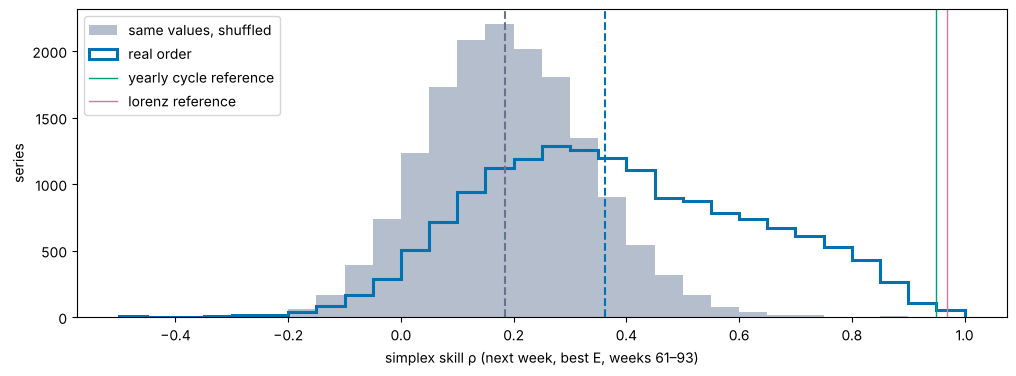

In [7]:
from joblib import Parallel, delayed

PANEL_N = 0  # 0 = all series


def real_vs_shuffled(uid, y):
    import warnings
    warnings.filterwarnings("ignore")
    out = {"unique_id": uid}
    for name, v in [("real", y), ("shuffled", np.random.default_rng(int(uid.split("_")[0])).permutation(y))]:
        try:
            out[name] = best_rho(v)[0]
        except Exception:
            out[name] = np.nan
    return out


g = train.sort(["unique_id", "ds"]).group_by("unique_id", maintain_order=True).agg(pl.col("y"))
jobs = list(zip(g["unique_id"], [np.asarray(v, float) for v in g["y"]]))
if PANEL_N:
    jobs = [jobs[i] for i in np.random.default_rng(bc.RANDOM_SEED).choice(len(jobs), PANEL_N, replace=False)]
rs = pd.DataFrame(Parallel(n_jobs=-1, batch_size=64)(delayed(real_vs_shuffled)(u, y) for u, y in jobs)).set_index("unique_id")
rs = rs.join(info["demand_type"]).dropna()

thr = rs["shuffled"].quantile(0.9)
print(f"{len(rs):,} series with a defined skill")
print(f"median rho: real {rs.real.median():.2f}, shuffled {rs.shuffled.median():.2f}")
print(f"real beats its own shuffle: {(rs.real > rs.shuffled).mean():.0%} (chance 50 %)")
print(f"real beats the 90th percentile of shuffled skill ({thr:.2f}): {(rs.real > thr).mean():.0%} (chance 10 %)")
print(rs.assign(beats=rs.real > rs.shuffled).groupby("demand_type")[["beats", "real", "shuffled"]].agg(
    {"beats": "mean", "real": "median", "shuffled": "median"}).round(2))

bins = np.arange(-0.5, 1.0001, 0.05)
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(rs.shuffled.clip(-0.499, 0.999), bins=bins, color="#94a3b8", alpha=0.7, label="same values, shuffled")
ax.hist(rs.real.clip(-0.499, 0.999), bins=bins, histtype="step", lw=2.2, color=palette[1], label="real order")
for v, c in [(rs.shuffled.median(), "#64748b"), (rs.real.median(), palette[1])]:
    ax.axvline(v, color=c, ls="--")
for k, c in [("yearly cycle", palette[3]), ("lorenz", palette[4])]:
    ax.axvline(own.loc[k, "rho"], color=c, lw=1, label=f"{k} reference")
ax.set_xlabel("simplex skill ρ (next week, best E, weeks 61–93)"); ax.set_ylabel("series"); ax.legend();

**Reading the result.** On the reference run about three in four series predict their next week better in real
order than shuffled (chance: one in two), and about half beat 9 in 10 shuffles (chance: one in ten). The order of
the weeks carries information, which is the minimum a forecast needs. The signal per item is modest, far from the
yearly-cycle and Lorenz references.

The whole-store total can fail this test even though it is the smoothest series: its level in weeks 61–93 never
occurs in weeks 1–60, so the nearest neighbours have nothing close to look up. A trend or level shift breaks
analog methods unless you scale or difference first.

## 3 · Similar states in other items

One item has about 50 past states to compare with. The panel has close to a million. Divide every item by its own
training mean (so a window is a shape, not a level), take every 26-week training window of every item that still
has 14 known weeks after it, and look up the windows closest to this item's last 26 training weeks. The item itself is
left out. Window length 26 and k = 50 were the best of a small grid on the validation weeks (window 4–52,
k 10–200).

library: 924,511 windows from 17,241 items


,neighbour,unique_id,department,window_ends,distance,weight
0,Hand wash lime eucalyptus 500ml,5886_S1,71,2024-02-21,1.398,0.027
1,Deli tuna Italian herb 90g,17073_S1,108,2024-09-25,1.502,0.025
2,Wet cat food classic mixed 12x85g,12056_S1,11,2024-02-07,1.549,0.024
3,Milk chocolate block peanut butter 250g,5241_S1,121,2024-05-22,1.592,0.023
4,Dark chocolate block salted caramel 250g,11827_S1,121,2024-05-22,1.619,0.023
5,Gnocchi traditional 500g,18454_S1,10,2024-09-18,1.676,0.022
6,Greeting card birthday female birds,589_S1,3,2024-03-20,1.677,0.022
7,Mini donuts mixed 15 pack 550g,12732_S1,12,2024-02-14,1.682,0.022
8,Deli tuna tomato chilli 90g,13161_S1,108,2024-09-25,1.713,0.021
9,Milk chocolate block rum and raisin 250g,9685_S1,121,2024-05-22,1.724,0.021


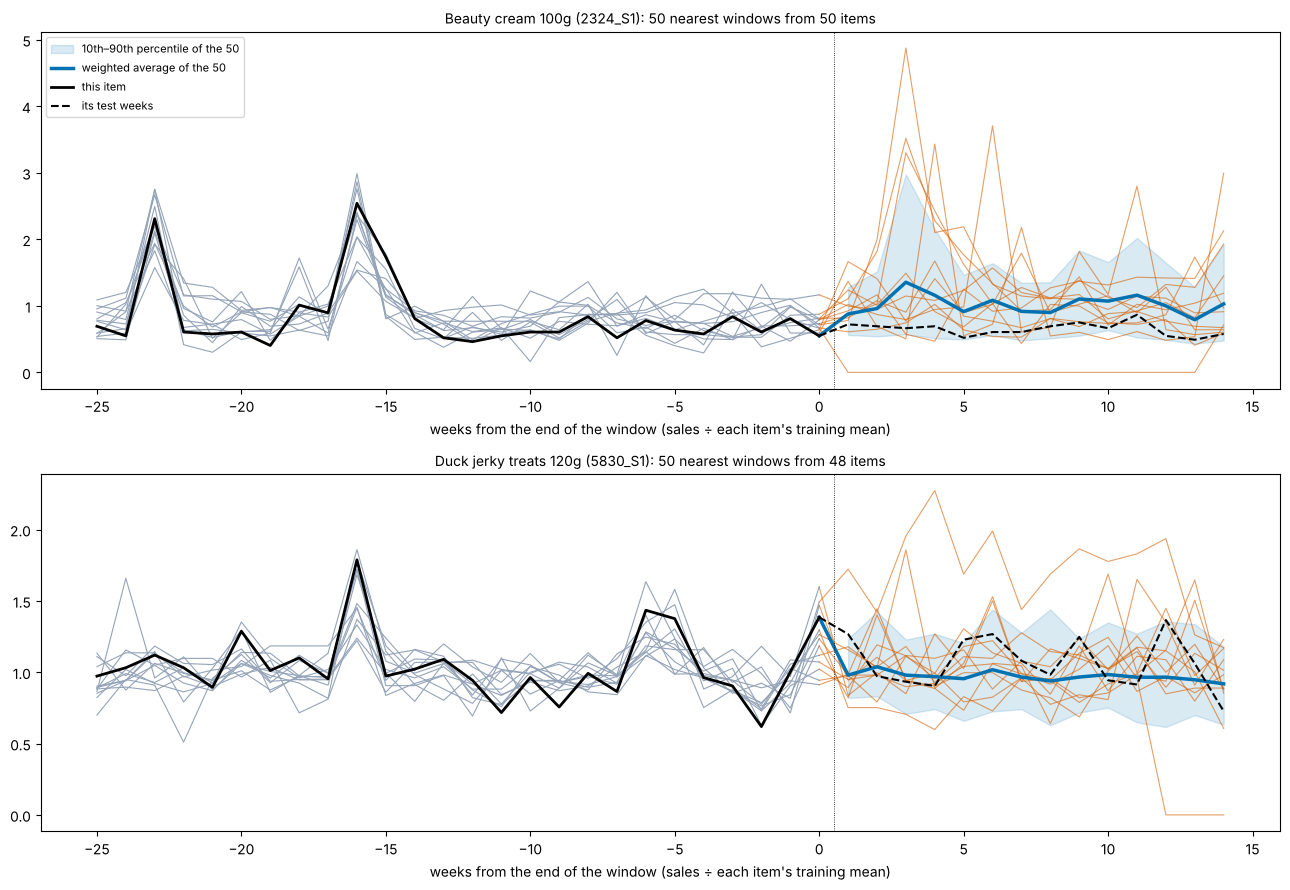

In [8]:
L_WIN, K_NB, SHOW = 26, 50, 12
ids = list(g["unique_id"])
ys = [np.asarray(v, float) for v in g["y"]]
dss = train.sort(["unique_id", "ds"]).group_by("unique_id", maintain_order=True).agg(pl.col("ds"))["ds"].to_list()
scale = np.array([y.mean() if y.mean() > 0 else 1.0 for y in ys])
X, own_i, end = [], [], []
for i, y in enumerate(ys):
    z = y / scale[i]
    for e in range(L_WIN, len(z) - bc.H + 1):
        X.append(z[e - L_WIN:e]); own_i.append(i); end.append(e)
X, own_i, end = np.asarray(X, np.float32), np.asarray(own_i), np.asarray(end)
library = NearestNeighbors(n_neighbors=K_NB + 200).fit(X)
print(f"library: {len(X):,} windows from {len(ys):,} items")


def analogs(uid, ax=None):
    i = ids.index(uid)
    q = (ys[i][-L_WIN:] / scale[i]).astype(np.float32)
    d, j = library.kneighbors(q[None, :])
    keep = own_i[j[0]] != i
    d, j = d[0][keep][:K_NB], j[0][keep][:K_NB]
    w = np.exp(-d / max(d[0], 1e-12)); w /= w.sum()
    fut = np.stack([ys[own_i[k]][end[k]:end[k] + bc.H] / scale[own_i[k]] for k in j])
    actual = test.filter(pl.col("unique_id") == uid).sort("ds")["y"].to_numpy() / scale[i]
    if ax is not None:
        hb, hf = np.arange(-L_WIN + 1, 1), np.arange(1, bc.H + 1)
        ax.fill_between(hf, np.quantile(fut, 0.1, axis=0), np.quantile(fut, 0.9, axis=0), color=palette[1], alpha=0.15, label="10th–90th percentile of the 50")
        for k in j[:SHOW]:
            o, e = own_i[k], end[k]
            ax.plot(hb, ys[o][e - L_WIN:e] / scale[o], color="#94a3b8", lw=0.8)
            ax.plot(np.r_[0, hf], np.r_[ys[o][e - 1], ys[o][e:e + bc.H]] / scale[o], color=palette[2], lw=0.8, alpha=0.6)
        ax.plot(np.r_[0, hf], np.r_[q[-1], w @ fut], color=palette[1], lw=2.5, label="weighted average of the 50")
        ax.plot(hb, q, color="k", lw=2, label="this item")
        ax.plot(np.r_[0, hf], np.r_[q[-1], actual], "k--", lw=1.5, label="its test weeks")
        ax.axvline(0.5, color="k", lw=0.6, ls=":")
        ax.set_title(f"{desc(uid)} ({uid}): 50 nearest windows from {len(set(own_i[j]))} items", fontsize=10)
        ax.set_xlabel("weeks from the end of the window (sales ÷ each item's training mean)")
    return pd.DataFrame({"neighbour": [desc(ids[own_i[k]]) for k in j], "unique_id": [ids[own_i[k]] for k in j],
                         "department": [info.loc[ids[own_i[k]], "department_id"] for k in j],
                         "window_ends": [dss[own_i[k]][end[k] - 1] for k in j], "distance": d.round(3), "weight": w.round(3)})


fig, axes = plt.subplots(2, 1, figsize=(13, 9))
nb_erratic = analogs(EXAMPLES["erratic"], axes[0])
analogs(EXAMPLES["smooth"], axes[1])
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
nb_erratic.head(10)

**Reading it.** The closest windows come from unrelated products in many departments, yet what followed them
brackets what this item did next. Scored on all series in the 14 test weeks, this pooled lookup (mean RMSSE 1.485)
beats both the item's own embedding (1.565) and repeating last week (Naive, 1.516), and ties AutoETS (1.482); the trained
global models (NHITSx 1.303) and Chronos-2 with covariates (1.294) are much better, because they also see prices and
promotions. Windows from many series are what a global model is trained on: this is one way to see why global
models can forecast items whose own 93 weeks look like noise.

Try: `analogs("<another unique_id>", plt.gca())`, or change `L_WIN`. Promotions are not in the windows; can you
see neighbours whose spike lines up with a promotion week of this item?

## 4 · Recurrence plots: has the series been here before?

A dot at (i, j) when the states at weeks i and j are close (Eckmann, Kamphorst and Ruelle 1987). The threshold is set
so that 10 % of pairs count as close. Diagonal lines are stretches of the past that repeat; **DET** is the share of
recurrent points on diagonal lines (length ≥ 2). Overlapping delay vectors alone produce diagonal lines, so again
the yardstick is the same values shuffled. `pyunicorn` computes both.

,DET,DET_shuffled_median
series,,
yearly cycle,0.71,0.17
lorenz,0.69,0.17
store,0.25,0.15
erratic,0.26,0.17
smooth,0.12,0.17
lumpy,0.19,0.05


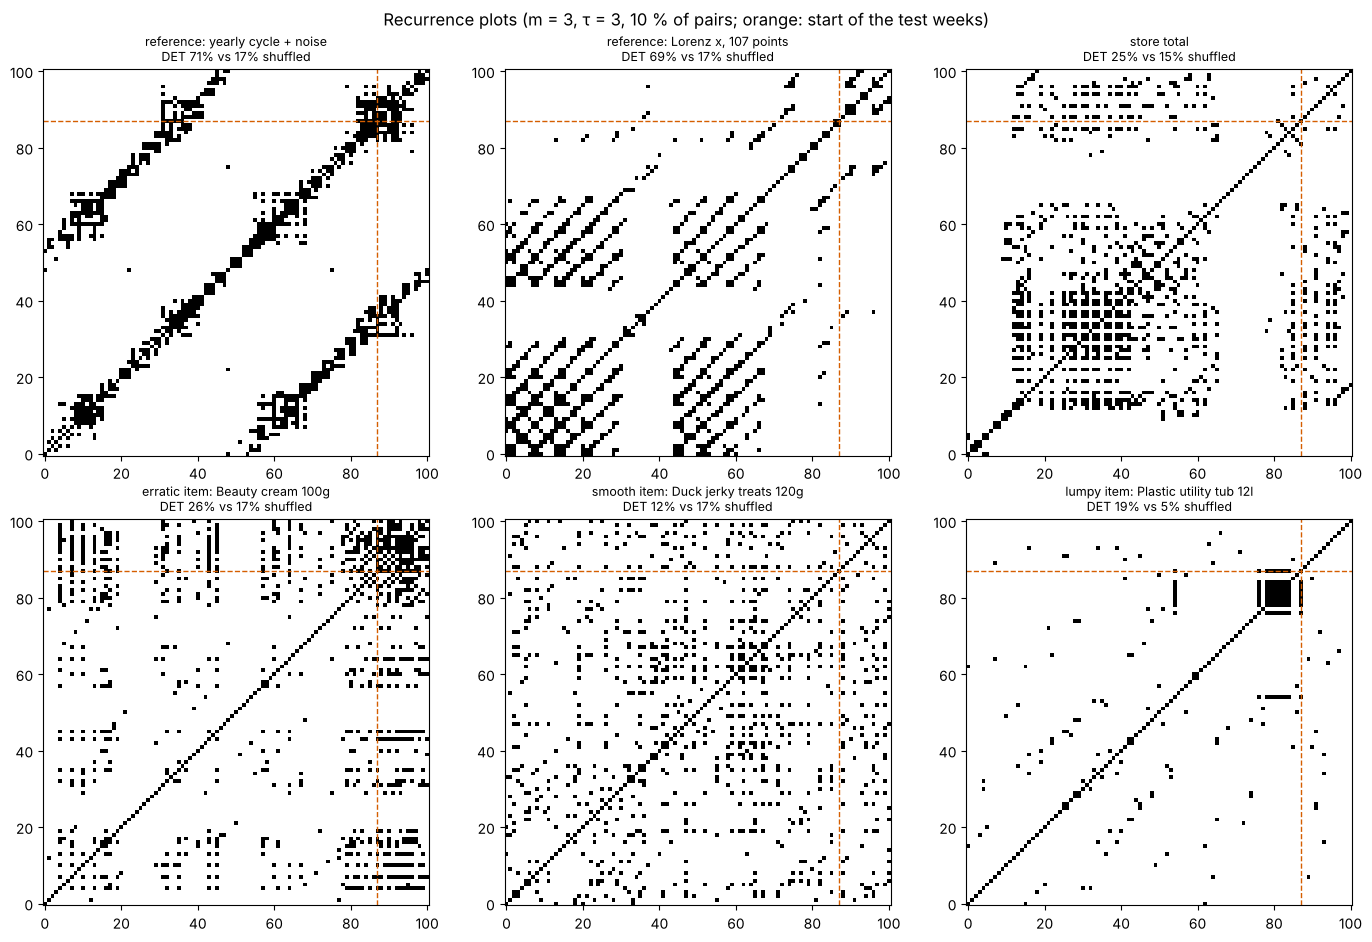

In [9]:
from pyunicorn.timeseries import RecurrencePlot

RR = 0.10


def rqa(y, m, tau):
    rp = RecurrencePlot(np.asarray(y, float), dim=m, tau=tau, recurrence_rate=RR, metric="euclidean", silence_level=2)
    return rp.recurrence_matrix(), rp.determinism(l_min=2)


keys = ["yearly cycle", "lorenz", "store", "erratic", "smooth", "lumpy"]
fig, axes = plt.subplots(2, 3, figsize=(14, 9.5))
det_rows = []
for ax, k in zip(axes.flat, keys):
    y = S[k]["y"]
    R, det = rqa(y, 3, TAU)
    dsh = np.median([rqa(np.random.default_rng(s).permutation(y), 3, TAU)[1] for s in range(10)])
    det_rows.append(dict(series=k, DET=det, DET_shuffled_median=dsh))
    ax.imshow(R, cmap="Greys", origin="lower", interpolation="nearest")
    if len(y) == n_all:
        b = N_TRAIN - (3 - 1) * TAU
        ax.axvline(b, color=palette[2], ls="--", lw=1); ax.axhline(b, color=palette[2], ls="--", lw=1)
    ax.set_title(f"{S[k]['label']}\nDET {det:.0%} vs {dsh:.0%} shuffled", fontsize=9)
fig.suptitle("Recurrence plots (m = 3, τ = 3, 10 % of pairs; orange: start of the test weeks)")
fig.tight_layout()
pd.DataFrame(det_rows).set_index("series").round(2)

**Reading it.** Blocks are periods spent in one state, white bands are weeks unlike anything else (promotions show
as isolated rows and columns), and diagonal lines are repeating stretches. The references are far above their
shuffles; the items and aggregates are close to theirs, some a little above and some below. A recurrence plot shows at a glance whether the
test weeks (top right) resemble anything in the training weeks.

## 5 · Choosing τ and m, and why the textbook recipe struggles here

* **Delay τ**: the first minimum of the average mutual information between x(t) and x(t+τ) (Fraser and Swinney
  1986), from `teaspoon`.
* **Dimension m**: the smallest m where the share of **false nearest neighbours** is near zero (Kennel, Brown and
  Abarbanel 1992): neighbours in m dimensions that fly apart when one more delay is added. From `neurokit2`, which
  flags a neighbour if either of Kennel's two tests fires (R_tol = 10, A_tol = 2).

Two pitfalls we hit, both from integer sales with many repeated values:

* `teaspoon` ranks values with ties broken in time order, which makes runs of zeros look dependent. A tiny jitter
  (1 % of the smallest gap between values) breaks ties at random instead.
* `teaspoon`'s own FNN function is not Kennel's rule: it counts a neighbour as false only if it passes the second
  test and stops at 10 %, so white noise of this length "embeds" in 3 dimensions. We use `neurokit2`.

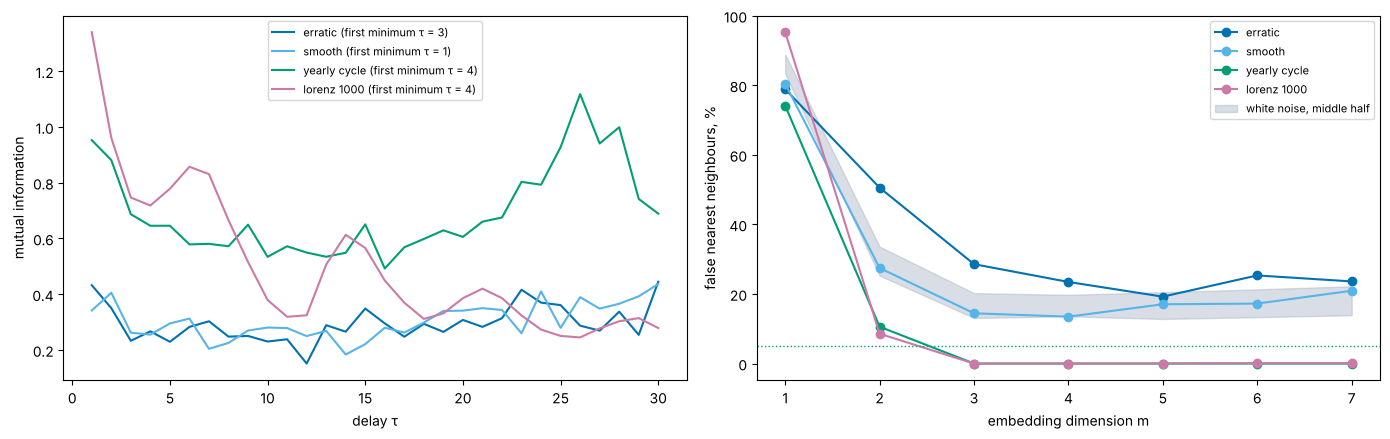

In [10]:
import neurokit2 as nk
from teaspoon.parameter_selection.MI_delay import MI_basic, MI_for_delay


def jitter(y, seed):
    u = np.unique(y)
    gap = np.min(np.diff(u)) if len(u) > 1 else 1.0
    return y + np.random.default_rng(seed).uniform(-0.01, 0.01, len(y)) * gap


def fnn_curve(y, tau, maxd=7):
    maxd = int(min(maxd, (len(y) - 21) // tau))
    _, inf = nk.complexity_dimension(jitter(y, 1), delay=tau, dimension_max=maxd, method="fnn", R=10.0, A=2.0,
                                     metric="euclidean", window=0)
    return 100 * np.asarray(inf["f3"], float)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
for k, c in [("erratic", palette[1]), ("smooth", palette[5]), ("yearly cycle", palette[3]), ("lorenz 1000", palette[4])]:
    y = S[k]["y"][:N_TRAIN] if len(S[k]["y"]) == n_all else S[k]["y"]
    yj = jitter(y, 2)
    mi = [MI_basic(yj[:-lag], yj[lag:]) for lag in range(1, 31)]
    tau = max(int(MI_for_delay(yj)), 1)
    a1.plot(range(1, 31), mi, color=c, label=f"{k} (first minimum τ = {tau})")
    a2.plot(range(1, 8), np.r_[fnn_curve(y, tau), [np.nan] * 7][:7], "o-", color=c, label=k)
noise = np.array([fnn_curve(np.random.default_rng(s).standard_normal(N_TRAIN), 3) for s in range(200)])
a2.fill_between(range(1, 8), *np.nanpercentile(noise, [25, 75], axis=0), color="#94a3b8", alpha=0.35, label="white noise, middle half")
a2.axhline(5, color=palette[3], ls=":", lw=1)
a1.set_xlabel("delay τ"); a1.set_ylabel("mutual information"); a1.legend(fontsize=8)
a2.set_xlabel("embedding dimension m"); a2.set_ylabel("false nearest neighbours, %"); a2.legend(fontsize=8)
fig.tight_layout()

**Reading it.** With 93 points the mutual-information curve is noisy and its first dip is usually a wiggle at a small
τ, not a quarter of a cycle. The items' false-neighbour curves sit near the white-noise band; the Lorenz and
yearly-cycle references drop to zero. On all 17,241 series (see the site), 81 % never reach 5 % false neighbours by
m = 7, against 99 % of white-noise runs. So the classic one-series recipe (pick τ, pick m, forecast from that
series' past) is weak on this data, even though section 2 shows the order of the weeks carries information.

## 6 · Is the structure nonlinear? S-map against surrogates

S-map (Sugihara 1994) fits one local linear map per prediction, with weights exp(−θ d / mean d). θ = 0 is a global
linear autoregression; skill that rises with θ suggests state-dependent behaviour. To check that a rise is more
than a linear process would give, repeat it on 19 IAAFT surrogates (Schreiber and Schmitz 1996, `pyunicorn`): same
values, nearly the same spectrum, no nonlinear structure. A pass means "not a stationary linear process":
promotions, trends and level shifts can pass too.

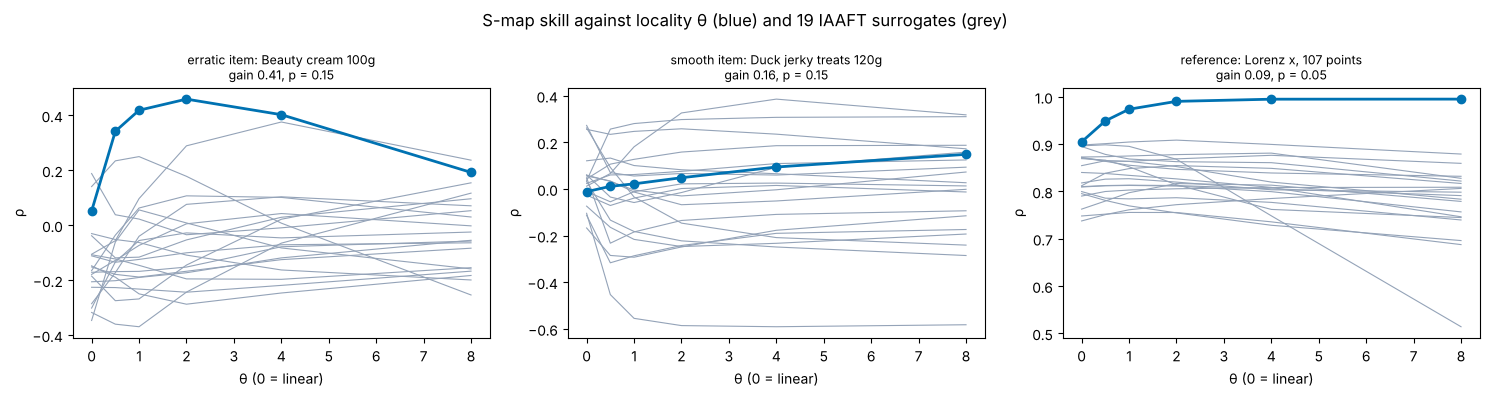

In [11]:
from pyunicorn.timeseries import Surrogates

THETAS = [0, 0.5, 1, 2, 4, 8]


def smap_curve(y, E):
    d = pd.DataFrame({"time": np.arange(len(y), dtype=float), "y": np.asarray(y, float)})
    out = []
    for th in THETAS:
        p = pyEDM.SMap(dataFrame=d, columns="y", target="y", lib=[1, LIB_END], pred=[LIB_END + 1, len(y)], E=E, Tp=1, theta=th)["predictions"]
        out.append(pyEDM.ComputeError(p["Observations"], p["Predictions"])["rho"])
    return np.array(out, float)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, ["erratic", "smooth", "lorenz"]):
    y = S[k]["y"][:N_TRAIN]
    E = int(own.loc[k, "best_E"])
    np.random.seed(1)
    sur = Surrogates(np.tile(y, (19, 1)), silence_level=2).refined_AAFT_surrogates(100)
    real = smap_curve(y, E)
    gains = []
    for s in sur:
        c = smap_curve(s, E); gains.append(np.nanmax(c[1:]) - c[0]); ax.plot(THETAS, c, color="#94a3b8", lw=0.8)
    gain = np.nanmax(real[1:]) - real[0]
    ax.plot(THETAS, real, "o-", color=palette[1], lw=2)
    ax.set_title(f"{S[k]['label']}\ngain {gain:.2f}, p = {(1 + np.sum(np.array(gains) >= gain)) / 20:.2f}", fontsize=9)
    ax.set_xlabel("θ (0 = linear)"); ax.set_ylabel("ρ")
fig.suptitle("S-map skill against locality θ (blue) and 19 IAAFT surrogates (grey)")
fig.tight_layout()

On all series (see the site), 16 % pass at p ≤ 0.05 against 5 % by chance, 23 % of erratic items.

## What to take away

* **The order of the weeks carries information.** Most series predict their own next week better than the same values
  shuffled. That is why forecasting works at all, and the pictures let you see it rather than take it on trust.
* **The patterns are shared across items.** States of unrelated products resemble an item's recent weeks, and what
  followed them sketches its next weeks. A library of windows from many series is what a global model learns from.
* **The most visible pattern comes from outside.** Promotions draw the star in the portraits and the stripes in the
  recurrence plots: the price calendar, which is why the promotion-aware models win.
* **As a single-series method it is weak here.** Takens assumes a deterministic, autonomous, noise-free system and long
  records; 93 weeks of counts driven by prices do not fit. Stark (1999) and Stark et al. (2003) extend the theorems to
  forced and stochastically forced systems, but they say nothing about how much data is enough.
* **Check the package against the paper.** Ties broke the mutual information and FNN tools until we added a jitter,
  and one package's FNN is not Kennel's rule.

### Exercises

1. Pick an item from your favourite department and run sections 1–4 on it. Does `COLOUR = "promo"` explain its cloud?
2. In section 2, divide each series by its training mean (or take differences) before `best_rho`. Does the store
   total pass the shuffle test then?
3. In section 3, change `L_WIN` to 8 and 52. Which window gives the tightest band around the test weeks?

### Sources

Takens (1981) *Detecting strange attractors in turbulence*, LNM 898 · Packard, Crutchfield, Farmer, Shaw (1980) PRL 45:712 ·
Sauer, Yorke, Casdagli (1991) *Embedology*, J. Stat. Phys. 65:579 · Fraser and Swinney (1986) PRA 33:1134 ·
Kennel, Brown, Abarbanel (1992) PRA 45:3403 · Eckmann, Kamphorst, Ruelle (1987) Europhys. Lett. 4:973 ·
Sugihara and May (1990) Nature 344:734 · Sugihara (1994) Phil. Trans. R. Soc. A 348:477 ·
Schreiber and Schmitz (1996) PRL 77:635 · Stark (1999) J. Nonlinear Sci. 9:255 · Stark et al. (2003) J. Nonlinear Sci. 13:519.